In [ ]:
'''>>>>> start CodeP3.2F25
    V.P. Carey ME249, Fall 2025

Intro to Neural Network Modeling 
Keras model for PV power system'''

#import useful packages
import keras
import pandas as pd
from keras.models import Sequential
import numpy as np
import keras.backend as kb
import tensorflow as tf
#the following 2 lines are only needed for Mac OS machines
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'


# ===== PART 1: Define raw data first, convert temp to Kelvin, then calculate median values =====
# Raw input data: Mode number, Air temp (degC), ID (W/sqm), load resistance (ohms)
xdata_raw = [[0., 10.0, 200.0, 24.3], 
 [1., 10.0, 200.0, 24.3], 
 [2., 10.0, 200.0, 24.3], 
 [0., 10.0, 200.0, 51.8], 
 [1., 10.0, 200.0, 51.8],
 [2., 10.0, 200.0, 51.8], 
 [0., 10.0, 200.0, 96.2], 
 [1., 10.0, 200.0, 96.2], 
 [2., 10.0, 200.0, 96.1], 
 [0., 10.0, 200.0, 170.1],
 [1., 10.0, 200.0, 170.1], 
 [2., 10.0, 200.0, 170.1], 
 [0., 10.0, 500.0, 7.0], 
 [1., 10.0, 500.0, 7.0], 
 [2., 10.0, 500.0, 7.0], 
 [0., 10.0, 500.0, 21.2], 
 [1., 10.0, 500.0, 21.2], 
 [2., 10.0, 500.0, 21.2], 
 [0., 10.0, 500.0, 43.2], 
 [1., 10.0, 500.0, 43.2], 
 [1., 10.0, 700.0, 4.9], 
 [2., 10.0, 700.0, 4.9], 
 [0., 10.0, 700.0, 14.3], 
 [1., 10.0, 700.0, 14.3], 
 [2., 10.0, 700.0, 14.3],
 [2., 10.0, 500.0, 43.2], 
 [0., 10.0, 500.0, 79.1], 
 [1., 10.0, 500.0, 79.1], 
 [2., 10.0, 500.0, 79.1], 
 [0., 10.0, 700.0, 4.8], 
 [0., 10.0, 700.0, 29.7], 
 [1., 10.0, 700.0, 29.7], 
 [2., 10.0, 700.0, 29.7], 
 [0., 10.0, 700.0, 55.3], 
 [1., 10.0, 700.0, 55.3], 
 [2., 10.0, 700.0, 55.3], 
 [0., 10.0, 1000.0, 3.92], 
 [1., 10.0, 1000.0, 3.92], 
 [2., 10.0, 1000.0, 3.92], 
 [0., 10.0, 1000.0, 11.7], 
 [1., 10.0, 1000.0, 11.7], 
 [2., 10.0, 1000.0, 11.7], 
 [0., 10.0, 1000.0, 25.2], 
 [1., 10.0, 1000.0, 25.2], 
 [2., 10.0, 1000.0, 25.2], 
 [0., 10.0, 1000.0, 41.6], 
 [1., 10.0, 1000.0, 41.6], 
 [2., 10.0, 1000.0, 41.6]]

#Part 1 output data: VL (V) and Power out (W)
ydata_raw = [[46.0, 87.3], 
 [27.9, 64.2], 
 [27.9, 32.1], 
 [46.0, 40.9], 
 [92.1, 163.9], 
 [59.5, 68.5], 
 [46.0, 22.0], 
 [92.1, 88.2], 
 [110.6, 127.2], 
 [46.0, 12.4], 
 [92.1, 49.9], 
 [184.2, 199.6], 
 [48.4, 335.3], 
 [20.8, 124.3], 
 [20.8, 62.1], 
 [48.4, 110.7], 
 [96.8, 442.9], 
 [63.1, 188.2], 
 [48.4, 54.3], 
 [96.9, 217.3], 
 [128.7, 383.6], 
 [48.4, 29.6], 
 [96.8, 118.7], 
 [193.7, 474.8], 
 [49.3, 496.1], 
 [20.4, 171.2], 
 [20.4, 85.6], 
 [49.3, 169.9], 
 [98.6, 679.9], 
 [59.7, 249.8], 
 [49.3, 81.8], 
 [98.6, 327.4], 
 [124.1, 518.9], 
 [49.305, 43.9], 
 [98.6, 175.8], 
 [197.2, 703.3], 
 [50.8, 658.9], 
 [23.1, 272.9], 
 [23.1, 136.4], 
 [50.8, 220.7], 
 [101.6, 883.1], 
 [69.0, 407.2], 
 [50.8, 102.5], 
 [101.6, 410.0], 
 [148.6, 877.2], 
 [50.8, 62.0], 
 [101.6, 248.3], 
 [203.2, 993.5]]

# Convert temperature from Celsius to Kelvin (K = degC + 273.15)
# Keep Mode (column 0) unchanged, convert Temp (column 1) to Kelvin
xdata_kelvin = [[row[0], row[1] + 273.15, row[2], row[3]] for row in xdata_raw]

print("===== Temperature Conversion =====")
print("First 3 samples (Celsius -> Kelvin):")
for i in range(3):
    print(f"  Mode={xdata_kelvin[i][0]:.1f}, Temp: {xdata_raw[i][1]:6.2f} °C  ->  {xdata_kelvin[i][1]:6.2f} K, ID={xdata_kelvin[i][2]:.1f}, RL={xdata_kelvin[i][3]:.3f}")
print()

# Convert to numpy arrays and calculate medians
xarray = np.array(xdata_kelvin)
yarray = np.array(ydata_raw)

# Calculate input variable medians from data
Tamed = np.median(xarray[:, 1])      # Air temperature median (K)
IDmed = np.median(xarray[:, 2])      # Irradiance (ID) median (W/sqm)
RLmed = np.median(xarray[:, 3])      # Load resistance median (ohms)

# Calculate output variable medians from data
VLmed = np.median(yarray[:, 0])      # Load voltage (VL) median (V)
Wdmed = np.median(yarray[:, 1])      # Power output (Wd) median (W)

print("===== Calculated Median Values =====")
print(f"Temperature median: {Tamed:.2f} K")
print(f"Irradiance median: {IDmed:.2f} W/sqm")
print(f"Load resistance median: {RLmed:.4f} ohms")
print(f"Voltage median: {VLmed:.2f} V")
print(f"Power median: {Wdmed:.2f} W\n")

# ===== PART 2: Create normalized input data array =====
# Normalize input data by dividing by medians
# Mode stays unnormalized (keep as is), Temperature/ID/RL normalized
xdata = []
for row in xdata_kelvin:
    xdata.append([row[0], row[1]/Tamed, row[2]/IDmed, row[3]/RLmed])

xarray = np.array(xdata)
print("===== Normalized Input Data =====")
print("First 5 rows (normalized):")
print(xarray[:5])
print(f"Input shape: {xarray.shape}\n")

# ===== PART 3: Create normalized output data array =====
# Normalize output data by dividing by medians
ydata = []
for row in ydata_raw:
    ydata.append([row[0]/VLmed, row[1]/Wdmed])

yarray = np.array(ydata)
print("===== Normalized Output Data =====")
print("First 5 rows (normalized):")
print(yarray[:5])
print(f"Output shape: {yarray.shape}\n")

# ===== PART 4: Split data into training (2/3) and validation (1/3) sets =====
# Set random seed for reproducibility
np.random.seed(42)

# Generate random indices and shuffle them
total_samples = len(xarray)
indices = np.arange(total_samples)
np.random.shuffle(indices)

# Calculate split point (2/3 for training, 1/3 for validation)
split_point = int(2/3 * total_samples)

# Split indices
train_indices = indices[:split_point]
val_indices = indices[split_point:]

# Create training and validation sets
x_train = xarray[train_indices]
y_train = yarray[train_indices]
x_val = xarray[val_indices]
y_val = yarray[val_indices]

print("===== Data Split =====")
print(f"Total samples: {total_samples}")
print(f"Training set size: {len(x_train)} ({len(x_train)/total_samples*100:.1f}%)")
print(f"Validation set size: {len(x_val)} ({len(x_val)/total_samples*100:.1f}%)")
print(f"\nTraining input shape: {x_train.shape}")
print(f"Training output shape: {y_train.shape}")
print(f"Validation input shape: {x_val.shape}")
print(f"Validation output shape: {y_val.shape}\n")

print("===== Median Values Summary =====")
print(f"Tamed = {Tamed:.2f}")
print(f"IDmed = {IDmed:.2f}")
print(f"RLmed = {RLmed:.4f}")
print(f"VLmed = {VLmed:.2f}")
print(f"Wdmed = {Wdmed:.2f}")

In [52]:
# define neural network model

#As seen below, we have created four dense layers. 
#A dense layer is a layer in neural network that’s fully connected. 
#In other words, all the neurons in one layer are connected to all other neurons in the next layer.
#In the first layer, we need to provide the input shape, which is 1 in our case. 
#The activation function we have chosen is elu, which stands for exponential linear unit. .

from keras import backend as K
#initialize weights with values between -0.2 and 0.5
initializer = keras.initializers.RandomUniform(minval= -0.2, maxval=0.5)

model = keras.Sequential([
    keras.layers.Dense(13, activation='elu', input_shape=[4],  kernel_initializer=initializer),
    keras.layers.Dense(26, activation='elu',  kernel_initializer=initializer),
    keras.layers.Dense(13, activation='elu', kernel_initializer=initializer),
    keras.layers.Dense(2,  kernel_initializer=initializer)
  ])


In [98]:
#We’re using RMSprop as our optimizer here. RMSprop stands for Root Mean Square Propagation. 
#It’s one of the most popular gradient descent optimization algorithms for deep learning networks. 
#RMSprop is an optimizer that’s reliable and fast.
#We’re compiling the mode using the model.compile function. The loss function used here 
#is mean squared error. After the compilation of the model, we’ll use the fit method with ~500 epochs.
#Number of epochs can be varied.

#from tf.keras import optimizers
rms = keras.optimizers.RMSprop(0.00005)
model.compile(loss='mean_absolute_error',optimizer=rms)


In [103]:
#After the compilation of the model, we’ll use the fit method with 500 epochs.
#I started with epochs value of 100 and then tested the model after training. 
#The prediction was not that good. Then I modified the number of epochs to 200 and tested the model again. 
#Accuracy had improved slightly, but figured I’d give it one more try. Finally, at 500 epochs 
#I found acceptable prediction accuracy.

#The fit method takes three parameters; namely, x, y, and number of epochs. 
#During model training, if all the batches of data are seen by the model once, 
#we say that one epoch has been completed.

# Add an early stopping callback
es = keras.callbacks.EarlyStopping(
    monitor='loss', 
    mode='min', 
    patience = 80, 
    restore_best_weights = True, 
    verbose=1)
# Add a checkpoint where loss is minimum, and save that model
mc = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='loss', 
                     mode='min',  verbose=1, save_best_only=True)

historyData = model.fit(x_train,y_train,epochs=800,callbacks=[es])

loss_hist = historyData.history['loss']
#The above line will return a dictionary, access it's info like this:
best_epoch = np.argmin(historyData.history['loss']) + 1
print ('best epoch = ', best_epoch)
print('smallest loss =', np.min(loss_hist))

model.save('./best_model.keras')

Epoch 1/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0340
Epoch 2/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0334
Epoch 3/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0335
Epoch 4/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0336
Epoch 5/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0338
Epoch 6/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0333
Epoch 7/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0335
Epoch 8/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0340
Epoch 9/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0338
Epoch 10/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0339
Epoch 11/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0336
Epoch 12/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0337
Epoch 13/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0335
Epoch 14/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0341
Epoch 15/800
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0337
Epoch 16/800
1/1 ━━

In [104]:


# This line of code can be used to reconstruct the saved model.

recon_model = keras.models.load_model("best_model.keras")

# the name of the model is now "recon_model". You can then use this model to do predictions for comparisons.
# See the previous project for code to do the comparisons.








row [0] M=1  T=283.1K  ID=500.0  RL=79.10  actual_power=169.9W  predicted_power=170.0W
row [1] M=1  T=283.1K  ID=1000.0  RL=11.70  actual_power=883.1W  predicted_power=868.5W
row [2] M=0  T=283.1K  ID=500.0  RL=79.10  actual_power=85.6W  predicted_power=85.5W
row [3] M=1  T=283.1K  ID=1000.0  RL=25.20  actual_power=410.0W  predicted_power=410.5W
row [4] M=2  T=283.1K  ID=700.0  RL=14.30  actual_power=496.1W  predicted_power=496.3W
row [5] M=1  T=283.1K  ID=1000.0  RL=3.92  actual_power=272.9W  predicted_power=273.4W
row [6] M=0  T=283.1K  ID=500.0  RL=7.00  actual_power=335.3W  predicted_power=335.5W
row [7] M=1  T=283.1K  ID=500.0  RL=43.20  actual_power=217.3W  predicted_power=216.9W
row [8] M=1  T=283.1K  ID=200.0  RL=51.80  actual_power=163.9W  predicted_power=164.5W
row [9] M=2  T=283.1K  ID=500.0  RL=43.20  actual_power=171.2W  predicted_power=171.4W
row [10] M=2  T=283.1K  ID=200.0  RL=96.10  actual_power=127.2W  predicted_power=126.7W
row [11] M=0  T=283.1K  ID=200.0  RL=51.80 

/tmp/ipykernel_1019621/154440754.py:46: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


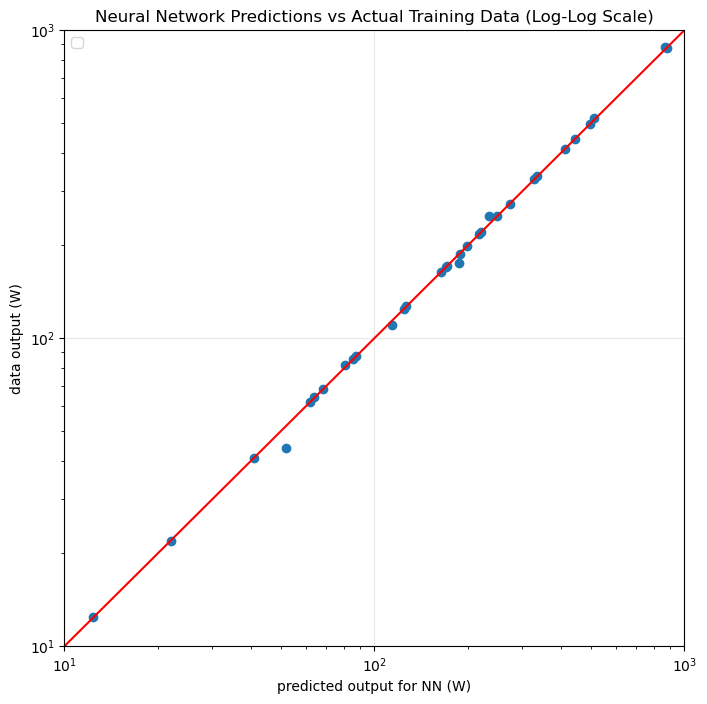

In [106]:
test = []
outpt=[]
predictions = model.predict(x_train, verbose=0)

# put in a loop to print comparison for all data points
for i in range(len(x_train)):
    # Use ALL 4 columns from training set
    test = [[x_train[i][0], x_train[i][1], x_train[i][2], x_train[i][3]]]
    testarray = np.array(test)
    outpt = model.predict(testarray, verbose=0)
    
    # Denormalize for display
    mode = x_train[i][0]
    temp = x_train[i][1] * Tamed
    irrad = x_train[i][2] * IDmed
    rl = x_train[i][3] * RLmed
    actual_power = y_train[i][1] * Wdmed
    pred_power = outpt[0][1] * Wdmed
    
    print(f'row [{i}] M={mode:.0f}  T={temp:.1f}K  ID={irrad:.1f}  RL={rl:.2f}  ' + \
          f'actual_power={actual_power:.1f}W  predicted_power={pred_power:.1f}W')

# SETTING UP PLOT
%matplotlib inline
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8]

# ========
# CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT
# Denormalize for plotting (use power: column 1)
predictions_denorm = predictions[:, 1] * Wdmed
actual_denorm = y_train[:, 1] * Wdmed

plt.scatter(predictions_denorm, actual_denorm)
plt.title('Neural Network Predictions vs Actual Training Data (Log-Log Scale)')
plt.xlabel('predicted output for NN (W)') 
plt.ylabel('data output (W)')
plt.loglog()
plt.xlim(xmax=1000, xmin=10)
plt.ylim(ymax=1000, ymin=10)

# Generate red y=x line using logspace for proper log scale
x_data = np.logspace(np.log10(10.0), np.log10(1000.0), num=100)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

row [0] M=0  T=283.1K  ID=200.0  RL=24.30  actual_power=87.3W  predicted_power=87.3W
row [1] M=1  T=283.1K  ID=200.0  RL=24.30  actual_power=64.2W  predicted_power=63.9W
row [2] M=2  T=283.1K  ID=200.0  RL=24.30  actual_power=32.1W  predicted_power=-208.8W
row [3] M=0  T=283.1K  ID=200.0  RL=51.80  actual_power=40.9W  predicted_power=40.9W
row [4] M=1  T=283.1K  ID=200.0  RL=51.80  actual_power=163.9W  predicted_power=164.5W
row [5] M=2  T=283.1K  ID=200.0  RL=51.80  actual_power=68.5W  predicted_power=68.3W
row [6] M=0  T=283.1K  ID=200.0  RL=96.20  actual_power=22.0W  predicted_power=22.0W
row [7] M=1  T=283.1K  ID=200.0  RL=96.20  actual_power=88.2W  predicted_power=73.6W
row [8] M=2  T=283.1K  ID=200.0  RL=96.10  actual_power=127.2W  predicted_power=126.7W
row [9] M=0  T=283.1K  ID=200.0  RL=170.10  actual_power=12.4W  predicted_power=12.3W
row [10] M=1  T=283.1K  ID=200.0  RL=170.10  actual_power=49.9W  predicted_power=73.1W
row [11] M=2  T=283.1K  ID=200.0  RL=170.10  actual_powe

/tmp/ipykernel_1019621/2855066255.py:48: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


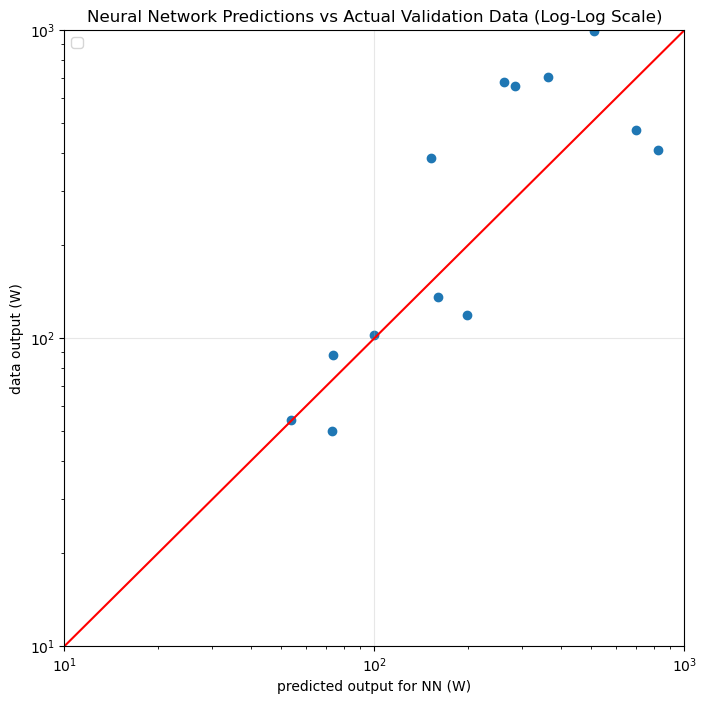


===== Validation Data Error Analysis =====
Mean Absolute Error (MAE): 202.0777 W
MAE as % of mean power: 64.99%
Root Mean Squared Error (RMSE): 259.9462 W
Max Absolute Error: 482.7832 W
Min Absolute Error: 0.4798 W
R-squared (R²): 0.2449


In [108]:
test = []
outpt=[]

# predictions on validation set
predictions = model.predict(x_val, verbose=0)

# put in a loop to print comparison for all data points
for i in range(len(xarray)):
    # Use ALL 4 columns: Mode, T_normalized, ID_normalized, RL_normalized
    test = [[xarray[i][0], xarray[i][1], xarray[i][2], xarray[i][3]]]
    testarray = np.array(test)
    outpt = model.predict(testarray, verbose=0)
    
    # Denormalize for display
    mode = xarray[i][0]
    temp = xarray[i][1] * Tamed
    irrad = xarray[i][2] * IDmed
    rl = xarray[i][3] * RLmed
    actual_power = yarray[i][1] * Wdmed
    pred_power = outpt[0][1] * Wdmed  # output index 1 is power
    
    print(f'row [{i}] M={mode:.0f}  T={temp:.1f}K  ID={irrad:.1f}  RL={rl:.2f}  ' + \
          f'actual_power={actual_power:.1f}W  predicted_power={pred_power:.1f}W')

# SETTING UP PLOT
%matplotlib inline
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8]

# ========
# CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT
# Denormalize for plotting (output index 1 is power)
predictions_denorm = predictions[:, 1] * Wdmed  # Power is column 1
actual_denorm = y_val[:, 1] * Wdmed             # Use validation data power

plt.scatter(predictions_denorm, actual_denorm)
plt.title('Neural Network Predictions vs Actual Validation Data (Log-Log Scale)')
plt.xlabel('predicted output for NN (W)') 
plt.ylabel('data output (W)')
plt.loglog()
plt.xlim(xmax=1000, xmin=10)
plt.ylim(ymax=1000, ymin=10)

# Generate red y=x line using logspace for proper log scale
x_data = np.logspace(np.log10(10.0), np.log10(1000.0), num=100)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Calculate Mean Absolute Error (MAE) for validation data
mae = np.mean(np.abs(predictions_denorm - actual_denorm))

print(f"\n===== Validation Data Error Analysis =====")
print(f"Mean Absolute Error (MAE): {mae:.4f} W")
print(f"MAE as % of mean power: {(mae / np.mean(actual_denorm)) * 100:.2f}%")

# Additional useful metrics
rmse = np.sqrt(np.mean((predictions_denorm - actual_denorm)**2))
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} W")

max_error = np.max(np.abs(predictions_denorm - actual_denorm))
min_error = np.min(np.abs(predictions_denorm - actual_denorm))
print(f"Max Absolute Error: {max_error:.4f} W")
print(f"Min Absolute Error: {min_error:.4f} W")

# R-squared (coefficient of determination)
ss_res = np.sum((actual_denorm - predictions_denorm)**2)
ss_tot = np.sum((actual_denorm - np.mean(actual_denorm))**2)
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared (R²): {r_squared:.4f}")

In [109]:
# Simplified version if you only have one Task 2.1 model available
input_conditions = [
    [10.0, 200, 50.0],
    [20.0, 200, 130.0],
    [10.0, 500, 40.0],
    [20.0, 500, 80.0],
    [20.0, 700, 30.0],
    [20.0, 700, 55.0],
    [10.0, 1000, 12.0],
    [20.0, 1000, 25.0],
    [20.0, 1000, 39.0]
]

results = []

for T_air_degC, I_D, R_L in input_conditions:
    T_air_K = T_air_degC + 273.15
    row_data = {'T_air': T_air_degC, 'I_D': I_D, 'R_L': R_L, 'powers': {}}
    
    # Predict power for M=0, 1, 2
    for mode in [0, 1, 2]:
        test_input = [[mode, T_air_K / Tamed, I_D / IDmed, R_L / RLmed]]
        test_array = np.array(test_input)
        outpt_power = model.predict(test_array, verbose=0)
        power_W = outpt_power[0][1] * Wdmed
        row_data['powers'][mode] = power_W
    
    # Predicted M_max,int is the mode with maximum power
    M_max_int = max(row_data['powers'], key=row_data['powers'].get)
    row_data['M_max_int_pred'] = M_max_int
    results.append(row_data)

# Display results
for idx, row in enumerate(results):
    print(f"Row {idx+1}: T={row['T_air']}°C, I_D={row['I_D']}, R_L={row['R_L']}")
    print(f"  M=0: {row['powers'][0]:.2f}W | M=1: {row['powers'][1]:.2f}W | M=2: {row['powers'][2]:.2f}W")
    print(f"  → Predicted M_max,int = {row['M_max_int_pred']}")

Row 1: T=10.0°C, I_D=200, R_L=50.0
  M=0: 41.47W | M=1: 170.95W | M=2: 62.54W
  → Predicted M_max,int = 1
Row 2: T=20.0°C, I_D=200, R_L=130.0
  M=0: 10.99W | M=1: 63.40W | M=2: 168.56W
  → Predicted M_max,int = 2
Row 3: T=10.0°C, I_D=500, R_L=40.0
  M=0: 55.76W | M=1: 230.15W | M=2: 156.83W
  → Predicted M_max,int = 1
Row 4: T=20.0°C, I_D=500, R_L=80.0
  M=0: 86.59W | M=1: 170.05W | M=2: 258.15W
  → Predicted M_max,int = 2
Row 5: T=20.0°C, I_D=700, R_L=30.0
  M=0: 81.99W | M=1: 332.18W | M=2: 503.86W
  → Predicted M_max,int = 2
Row 6: T=20.0°C, I_D=700, R_L=55.0
  M=0: 52.83W | M=1: 190.36W | M=2: 361.60W
  → Predicted M_max,int = 2
Row 7: T=10.0°C, I_D=1000, R_L=12.0
  M=0: 213.81W | M=1: 871.57W | M=2: 831.02W
  → Predicted M_max,int = 1
Row 8: T=20.0°C, I_D=1000, R_L=25.0
  M=0: 103.46W | M=1: 435.25W | M=2: 881.90W
  → Predicted M_max,int = 2
Row 9: T=20.0°C, I_D=1000, R_L=39.0
  M=0: 67.27W | M=1: 251.11W | M=2: 574.53W
  → Predicted M_max,int = 2
